# TimeDiff 尾部增權：完整 PPO 對照與 v2、v3 比較

比較六個本次組別與 v2、v3 各五個歷史組別。所有模型皆以 **validation Sharpe** 選模；test 不參與選擇。

本次缺少的三個對照已補齊：真實回放 PR30、真實回放 PR10、完整歷史分布條件 TimeDiff。每組 seeds 0–9、5 workers、名義 500,000 步（實際 532,480），每 25,000 名義步保存 checkpoint。

這份 notebook 是**唯讀分析入口**，重新執行只會讀取既有結果。訓練、評估與圖表生成程式在同一資料夾，原實驗檔案不會被覆寫。


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

def locate_root():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "finrl/experiments/scenario_mix.py").exists(): return p
        if (p / "FinRL_Exp/finrl/experiments/scenario_mix.py").exists(): return p / "FinRL_Exp"
    raise FileNotFoundError("請從 FinRL_Exp 或其 analysis 子目錄執行")

ROOT = locate_root()
OUT = ROOT / "results/scenario_mix/comprehensive_20261019"
FIG = OUT / "figures"
summary = pd.read_csv(OUT / "selected_summary.csv")
selected = pd.read_csv(OUT / "selected_metrics.csv")
all_steps = pd.read_csv(OUT / "all_checkpoint_metrics.csv")
config = pd.read_csv(OUT / "group_configurations.csv")
paired = pd.read_csv(OUT / "paired_seed_differences.csv")
manifest = json.loads((OUT / "analysis_manifest.json").read_text())
assert len(all_steps) == 5400 and len(selected) == 270 and len(config) == 16
CURRENT = ["REAL_ONLY", "REAL_REPLAY_PR30_B50", "REAL_REPLAY_PR10_B50", "FULL_B50", "PR30_B50", "PR10_B50"]
ORDER = CURRENT + [f"{v}_{g}" for v in ["V2", "V3"] for g in ["A", "B20", "B50", "B70", "B90"]]

def show_figure(name, width=1450):
    display(Image(filename=str(FIG / f"{name}.png"), width=width))

def metric_table(split, common=False):
    frame = pd.read_csv(OUT / "selected_summary_common_seeds0_2.csv") if common else summary
    z = frame[frame.split == split].set_index("group").loc[ORDER]
    result = pd.DataFrame(index=z.index)
    result["seeds"] = z.n_seeds
    for metric, label in [("return_pct", "累積報酬 %"), ("cagr_net_pct", "年化淨報酬 %"), ("sharpe", "Sharpe"), ("sortino", "Sortino"), ("calmar", "Calmar"), ("mdd_pct", "最大回撤 %"), ("es95_daily_pct", "每日 ES95 %"), ("stock_weight_pct", "平均股票曝險 %")]:
        digits = 3 if metric in ["sharpe", "sortino", "calmar"] else 2
        result[label] = [f"{a:.{digits}f} ± {b:.{digits}f}" for a,b in zip(z[f"{metric}_mean"], z[f"{metric}_sd"])]
    return result

def additional_table(split, kind):
    z = summary[summary.split == split].set_index("group").loc[ORDER]
    measures = {
        "risk": [("volatility_pct", "年化波動 %"), ("var95_daily_pct", "每日 VaR95 %"), ("es95_daily_pct", "每日 ES95 %"), ("worst_21d_return_pct", "最差 21 日報酬 %"), ("var95_21d_pct", "21 日 VaR95 %"), ("es95_21d_pct", "21 日 ES95 %")],
        "allocation": [("annual_turnover", "年化換手 倍"), ("fee_factor_drag_pct", "費用因子拖累 %"), ("stock_weight_pct", "股票曝險 %"), ("mean_largest_stock_weight_pct", "平均最大單股 %"), ("max_single_stock_weight_pct", "期間最大單股 %"), ("concentrated_over80_pct", "單股逾 80% 日數 %"), ("action_bound_fraction_pct", "動作邊界比例 %")],
    }
    result = pd.DataFrame(index=z.index)
    for metric, label in measures[kind]:
        result[label] = [f"{a:.2f} ± {b:.2f}" for a,b in zip(z[f"{metric}_mean"], z[f"{metric}_sd"])]
    return result

display(Markdown(f"資料核對：**{len(config)} 組、90 個 runs、1,800 個 checkpoints、5,400 次 split 評估**。"))


資料核對：**16 組、90 個 runs、1,800 個 checkpoints、5,400 次 split 評估**。

## 主要結果

**結論：PR30 是目前較值得後續驗證的候選，但本次尚未建立相對 real-only 或一般合成增強的穩定優勢。** 三個缺少的對照均已補訓，共 30 個新 runs、600 個 checkpoints，訓練耗時約 54 分鐘。比較涵蓋本次六組、v2 與 v3 各五組，共 90 個 runs、1,800 個 checkpoints；全部完成 train／validation／test 共 5,400 次連續評估。選模全程只使用 validation Sharpe。

**本次六組的 test 點估：** PR30 的平均年化淨報酬 11.69%、Sharpe 0.573、最大回撤 25.90%、21 日 ES95 9.89%；real-only 分別為 11.10%、0.555、26.63%、10.24%。PR30 減 real-only 的年化淨報酬差為 +0.595（95% 配對 bootstrap 區間 -0.598 至 +1.715） 個百分點，Sharpe 差為 +0.018（95% 配對 bootstrap 區間 -0.030 至 +0.065）；最大回撤與 21 日 ES95 的差異區間也跨過 0，尚不能把平均改善視為已確認的效果。

**補上的控制組釐清了什麼：** Full 合成減 real-only 的年化淨報酬差為 +0.065（95% 配對 bootstrap 區間 -1.081 至 +1.347） 個百分點；真實 PR30 回放也沒有一致改善。真實 PR10 回放的年化淨報酬差為 -0.837（95% 配對 bootstrap 區間 -1.552 至 -0.114） 個百分點，且沒有伴隨明確尾部風險改善。單純增加同樣風險時期的練習，並不足以保證較好的 test 表現。

**生成路徑相對真實回放的風險訊號：** PR30 合成減配對真實 PR30 回放的 21 日 ES95 差為 -0.561（95% 配對 bootstrap 區間 -1.107 至 -0.066） 個百分點，負值代表損失幅度下降；這項探索性區間未跨 0。相對 Full 合成的差則為 -0.378（95% 配對 bootstrap 區間 -0.897 至 +0.105），仍跨 0。這不足以確認尾部增權全面優於一般合成增強，而且多重比較未校正。

**PR10 增權較強，PPO 卻沒有相應改善：** PR10 的 test 年化淨報酬為 10.80%、Sharpe 0.548、最大回撤 26.78%。其年化報酬的 seed 標準差只有 0.58 個百分點，低於 PR30 的 2.61，但「訓練 seed 間較穩定」與「市場尾部風險較低」是不同的判準。合成資料實際 PR10 占比已由 Full 的 9.7% 提升到 PR30 的 17.0%、PR10 的 30.1%，仍不能用這個比例直接推論 PPO 風險表現。

**訓練歷程與選模敏感度：** PR30 在 train／validation／test 的選中模型平均 Sharpe 為 1.090／1.195／0.573。不同市場期間與 validation 選擇偏差都會影響這個落差，不能全歸因於過度擬合。固定 500k 時，PR30 的 test Sharpe 為 0.588，real-only 為 0.591；PR10 為 0.439，低於其選中模型。完整步數曲線顯示，多訓練並不一致帶來改善；此敏感度分析沒有用來更換選模規則。

**持股與市場壓力：** 本次六組的平均股票曝險仍約 88–91%。PR30 的平均最大單股權重為 22.54%，real-only 為 15.34%，PR10 為 13.08%。PR30 seed 7 的 test 平均 MSFT 權重約 68.64%、最大回撤 32.44%；Full seed 7 的平均 MSFT 權重約 76.73%、最大回撤 33.45%。平均持股圖會稀釋這些集中部位，因此同時保留逐 seed 集中度與個別異常值表，所有 seeds 均納入結果。2022 年各本次組別平均仍虧損約 19–20%，不能稱為已學會有效避開危機。

**與 v2／v3 的比較：** 統一評估下，v3 B50 的平均 test Sharpe 為 0.597、年化淨報酬 11.35%，是本表 Sharpe 點估最高的組別；v2 B50 的 Sharpe 為 0.568。限制共同 seeds 0–2 時，PR30 的 Sharpe 為 0.530、PR10 為 0.540，排序與十個 seeds 時不同。v2 B90 的回撤較低（22.18%），同時股票曝險只有 76.19%、年化報酬 8.43%。舊組別只有三個 seeds，訓練 TRF、成本、生成資料與執行環境也不同；這些是歷史參照，不能作為抽樣方法的純因果比較。

**被動參照與成本：** 初始現金與十檔股票各 1/11 的買入持有，在 test 的年化淨報酬為 11.93%、Sharpe 0.598、最大回撤 26.61%。本次六組的平均 Sharpe 均未超過此參照；PR30 的 21 日 ES95 較低，但報酬／Sharpe 的取捨仍需一起看。

**優先改善方向：** 先修正生成資料的跨股票聯動與 OHLC 一致性，再考慮加強尾部比例。本次三批生成路徑的股票平均相關性約 0.173–0.218，配對真實時期約 0.337–0.382，high／low 原始特徵仍各有約 20–22% 需要修正。這些是可直接觀察的資料差異，但本次尚未單獨實驗其對 PPO 的因果影響。後續若要確認 PR30 效果，應在固定規則下增加獨立生成器／抽樣 seeds 與未用於選模的市場區段；不要依本次 test 曲線回頭挑步數或調整尾部比例。

## 實驗設定與公平比較

- Train：2010–2017；validation：2018–2019；test：2020–2025。各 split 獨立以現金與十檔股票各 1/11 建倉，計入建倉成本。
- 本次 B50 各組的替換機率皆為 50%。真實回放組重用對應 PR30／PR10 合成組的 anchor、抽樣配額與重複權重，把生成未來替換成真實未來。所有訓練行情仍落在 train 期間。
- Full 組的條件全部從完整歷史分布抽取；PR30／PR10 組使用 70% 完整池＋30% 尾部池。完整池本身也包含尾部。
- PR 分位數以十檔股票每日等權組合的 21 日累積報酬定義，波動率為同段每日組合 log return 的年化樣本標準差；歷史視窗、回報與波動率成對保留。B50 下額外尾部來源池約占全部 episodes 的 15%，不代表實際尾部行情只有 15%。
- 新 Full 組與原 PR30、PR10 組各有 1,400 條完整池路徑逐值相同（歷史視窗、條件、生成特徵及 OHLC 皆相同），僅另外 600 條的條件來源改變。
- v2、v3 保留既有訓練模型，全部以共同價格、修正後 TRF 與 0.25% 成本重算。v3 訓練時無交易成本；v2／v3 訓練時使用舊 TRF。它們也使用不同生成器／固定情境與執行環境，不能將差異全部歸因於抽樣。
- 舊固定情境資料共 6,039 條，實際條件為（21 日報酬、年化波動）＝（−10%、50%）、（−23%、100%）、（−36%、140%），各 2,013 條。本次每批 2,000 條，使用另行重訓的同一 TimeDiff checkpoint；生成器訓練期為 2005–2017，條件抽樣期為 2010–2017。
- v2 的完整訓練歷程來自 `v2_rewardlog`；15 個原 `v2_sharpe` 已選模型另以權重逐項核對，避免重複計入同一模型。


,group,n_seeds,training_trf,train_commission,evaluation_commission,replacement_probability,replacement_source,condition_policy,torch_version
0,REAL_ONLY,10,fixed,0.0025,0.0025,0.0,none,ordinary_real,2.13.0
1,REAL_REPLAY_PR30_B50,10,fixed,0.0025,0.0025,0.5,paired_real,full70_tail30_PR30,2.13.0
2,REAL_REPLAY_PR10_B50,10,fixed,0.0025,0.0025,0.5,paired_real,full70_tail30_PR10,2.13.0
3,FULL_B50,10,fixed,0.0025,0.0025,0.5,generated,full100,2.13.0
4,PR30_B50,10,fixed,0.0025,0.0025,0.5,generated,full70_tail30_PR30,2.13.0
5,PR10_B50,10,fixed,0.0025,0.0025,0.5,generated,full70_tail30_PR10,2.13.0
6,V2_A,3,legacy,0.0025,0.0025,0.0,none,ordinary_real,2.9.1+cu128
7,V2_B20,3,legacy,0.0025,0.0025,0.2,generated,legacy_fixed_scenarios,2.9.1+cu128
8,V2_B50,3,legacy,0.0025,0.0025,0.5,generated,legacy_fixed_scenarios,2.9.1+cu128
9,V2_B70,3,legacy,0.0025,0.0025,0.7,generated,legacy_fixed_scenarios,2.9.1+cu128


,資料批次,路徑數,不同歷史視窗,不同收盤路徑,報酬 MAE 百分點,波動 MAE 百分點
0,Full100,2000,430,2000,1.565,2.258
1,Full70+PR30,2000,415,2000,1.578,2.223
2,Full70+PR10,2000,397,2000,1.626,2.264


,資料批次,實際 PR10 占比 %,實際 PR30 占比 %,生成股票相關性,配對真實相關性,high 修正 %,low 修正 %
0,Full100,9.7,30.35,0.173,0.337,22.489,20.924
1,Full70+PR30,17.0,45.35,0.186,0.362,21.685,21.126
2,Full70+PR10,30.1,51.20,0.218,0.382,20.728,20.595


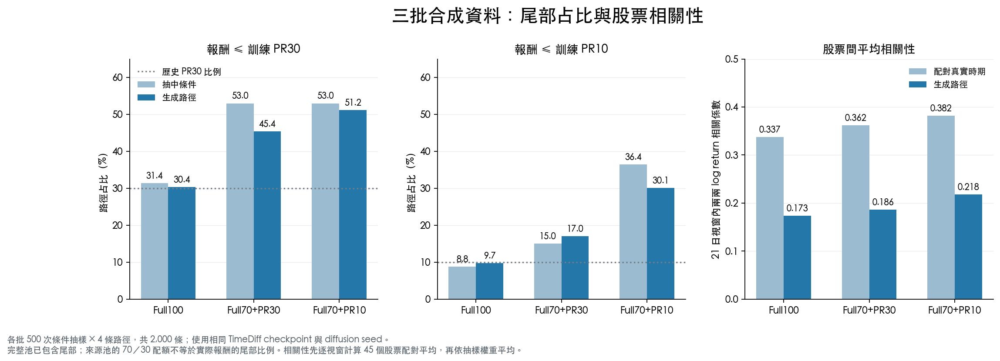

In [2]:
display(config[["group", "n_seeds", "training_trf", "train_commission", "evaluation_commission", "replacement_probability", "replacement_source", "condition_policy", "torch_version"]])
quality = pd.read_csv(OUT / "generation_quality_comparison.csv")
display(quality[["dataset", "paths", "unique_histories", "unique_close_paths", "return_mae_pp", "vol_mae_pp"]].rename(columns={"dataset":"資料批次", "paths":"路徑數", "unique_histories":"不同歷史視窗", "unique_close_paths":"不同收盤路徑", "return_mae_pp":"報酬 MAE 百分點", "vol_mae_pp":"波動 MAE 百分點"}).round(3))
display(quality[["dataset", "realized_pr10_pct", "realized_pr30_pct", "mean_stock_correlation", "paired_real_stock_correlation", "high_correction_pct", "low_correction_pct"]].rename(columns={"dataset":"資料批次", "realized_pr10_pct":"實際 PR10 占比 %", "realized_pr30_pct":"實際 PR30 占比 %", "mean_stock_correlation":"生成股票相關性", "paired_real_stock_correlation":"配對真實相關性", "high_correction_pct":"high 修正 %", "low_correction_pct":"low 修正 %"}).round(3))
show_figure("10_generation_tail_comparison")


## 各組 train、validation、test 指標

表中為 **seed 平均 ± 樣本標準差**；標準差不是信賴區間。最大回撤採正的損失幅度；VaR95 與 ES95 損失記正、收益記負，越低越好。完整 CSV 另含 Sortino、波動率、換手、費用因子拖累與集中度等指標。

Train 指標是選中模型在真實訓練期間的連續回測，與訓練過程中的隨機 episode reward 不同。期間長度不同，跨 split 比較優先使用年化報酬、Sharpe 與風險指標。


### Train 2010–2017

,seeds,累積報酬 %,年化淨報酬 %,Sharpe,Sortino,Calmar,最大回撤 %,每日 ES95 %,平均股票曝險 %
group,,,,,,,,,
REAL_ONLY,10,230.31 ± 37.07,16.06 ± 1.62,1.089 ± 0.055,1.585 ± 0.088,1.205 ± 0.106,13.36 ± 0.80,1.98 ± 0.11,89.91 ± 1.78
REAL_REPLAY_PR30_B50,10,261.80 ± 105.36,17.09 ± 3.52,1.138 ± 0.125,1.669 ± 0.222,1.296 ± 0.220,13.19 ± 0.93,1.98 ± 0.15,89.93 ± 3.48
REAL_REPLAY_PR10_B50,10,233.48 ± 42.06,16.19 ± 1.77,1.111 ± 0.083,1.618 ± 0.130,1.256 ± 0.150,12.98 ± 1.31,1.95 ± 0.13,89.74 ± 1.79
FULL_B50,10,206.56 ± 12.22,15.05 ± 0.57,1.014 ± 0.087,1.470 ± 0.123,1.088 ± 0.138,14.19 ± 2.93,2.02 ± 0.23,90.80 ± 2.31
PR30_B50,10,231.66 ± 41.97,16.11 ± 1.75,1.090 ± 0.132,1.597 ± 0.206,1.219 ± 0.245,13.64 ± 2.80,1.98 ± 0.21,87.98 ± 4.71
PR10_B50,10,211.34 ± 13.19,15.27 ± 0.61,1.052 ± 0.033,1.525 ± 0.052,1.169 ± 0.084,13.11 ± 0.50,1.96 ± 0.04,90.97 ± 1.30
V2_A,3,215.22 ± 6.58,15.46 ± 0.30,1.044 ± 0.016,1.518 ± 0.023,1.187 ± 0.024,13.05 ± 0.35,1.99 ± 0.01,90.03 ± 0.63
V2_B20,3,204.91 ± 12.03,14.97 ± 0.57,1.028 ± 0.028,1.487 ± 0.039,1.198 ± 0.075,12.55 ± 0.59,1.97 ± 0.07,91.05 ± 3.67
V2_B50,3,206.62 ± 2.62,15.06 ± 0.12,1.042 ± 0.006,1.508 ± 0.009,1.143 ± 0.018,13.20 ± 0.14,1.96 ± 0.00,91.07 ± 0.27


**尾部風險與波動**

,年化波動 %,每日 VaR95 %,每日 ES95 %,最差 21 日報酬 %,21 日 VaR95 %,21 日 ES95 %
group,,,,,,
REAL_ONLY,13.69 ± 0.84,1.36 ± 0.08,1.98 ± 0.11,-10.92 ± 1.33,4.53 ± 0.27,6.14 ± 0.40
REAL_REPLAY_PR30_B50,13.79 ± 1.27,1.36 ± 0.11,1.98 ± 0.15,-10.57 ± 1.54,4.50 ± 0.37,6.02 ± 0.49
REAL_REPLAY_PR10_B50,13.52 ± 0.91,1.35 ± 0.09,1.95 ± 0.13,-10.42 ± 0.38,4.44 ± 0.48,5.98 ± 0.53
FULL_B50,13.98 ± 1.75,1.38 ± 0.12,2.02 ± 0.23,-10.82 ± 1.75,4.78 ± 0.77,6.33 ± 0.88
PR30_B50,13.82 ± 1.56,1.35 ± 0.12,1.98 ± 0.21,-10.58 ± 1.73,4.54 ± 0.77,6.08 ± 0.86
PR10_B50,13.54 ± 0.26,1.35 ± 0.03,1.96 ± 0.04,-10.37 ± 0.33,4.55 ± 0.17,6.09 ± 0.15
V2_A,13.80 ± 0.18,1.36 ± 0.01,1.99 ± 0.01,-11.19 ± 0.54,4.57 ± 0.14,6.23 ± 0.02
V2_B20,13.61 ± 0.53,1.36 ± 0.07,1.97 ± 0.07,-10.78 ± 0.62,4.54 ± 0.20,6.12 ± 0.21
V2_B50,13.49 ± 0.05,1.33 ± 0.01,1.96 ± 0.00,-10.36 ± 0.15,4.53 ± 0.00,6.08 ± 0.02


**交易成本與持股集中度**

...

,seeds,累積報酬 %,年化淨報酬 %,Sharpe,Sortino,Calmar,最大回撤 %,每日 ES95 %,平均股票曝險 %
group,,,,,,,,,
REAL_ONLY,10,87.93 ± 10.95,11.10 ± 1.05,0.555 ± 0.056,0.790 ± 0.082,0.423 ± 0.066,26.63 ± 2.63,2.74 ± 0.19,90.00 ± 1.94
REAL_REPLAY_PR30_B50,10,89.44 ± 14.55,11.23 ± 1.42,0.553 ± 0.053,0.787 ± 0.077,0.421 ± 0.054,26.87 ± 2.19,2.78 ± 0.20,90.39 ± 2.74
REAL_REPLAY_PR10_B50,10,80.13 ± 19.73,10.26 ± 1.90,0.514 ± 0.076,0.730 ± 0.107,0.377 ± 0.084,27.62 ± 2.17,2.73 ± 0.19,89.79 ± 1.96
FULL_B50,10,90.11 ± 31.46,11.16 ± 2.86,0.542 ± 0.093,0.771 ± 0.136,0.412 ± 0.087,27.10 ± 2.48,2.78 ± 0.29,90.89 ± 2.20
PR30_B50,10,95.25 ± 28.48,11.69 ± 2.61,0.573 ± 0.079,0.820 ± 0.114,0.452 ± 0.079,25.90 ± 2.94,2.75 ± 0.26,88.36 ± 4.41
PR10_B50,10,84.84 ± 5.85,10.80 ± 0.58,0.548 ± 0.031,0.778 ± 0.045,0.406 ± 0.036,26.78 ± 1.13,2.70 ± 0.06,90.91 ± 1.52
V2_A,3,88.21 ± 9.54,11.13 ± 0.95,0.552 ± 0.040,0.784 ± 0.058,0.415 ± 0.039,26.92 ± 0.41,2.75 ± 0.05,90.36 ± 0.85
V2_B20,3,75.57 ± 8.99,9.85 ± 0.94,0.507 ± 0.045,0.718 ± 0.066,0.374 ± 0.033,26.42 ± 0.23,2.68 ± 0.05,91.19 ± 3.50
V2_B50,3,87.61 ± 0.72,11.09 ± 0.07,0.568 ± 0.005,0.806 ± 0.007,0.424 ± 0.009,26.24 ± 0.42,2.67 ± 0.01,91.05 ± 0.10


**尾部風險與波動**

,年化波動 %,每日 VaR95 %,每日 ES95 %,最差 21 日報酬 %,21 日 VaR95 %,21 日 ES95 %
group,,,,,,
REAL_ONLY,19.07 ± 1.29,1.62 ± 0.14,2.74 ± 0.19,-23.81 ± 2.01,6.63 ± 0.72,10.24 ± 0.83
REAL_REPLAY_PR30_B50,19.28 ± 1.21,1.65 ± 0.17,2.78 ± 0.20,-24.09 ± 1.25,6.83 ± 0.86,10.45 ± 0.81
REAL_REPLAY_PR10_B50,19.06 ± 1.30,1.62 ± 0.12,2.73 ± 0.19,-23.29 ± 1.35,6.64 ± 0.61,10.23 ± 0.70
FULL_B50,19.44 ± 2.24,1.66 ± 0.26,2.78 ± 0.29,-23.75 ± 1.37,6.62 ± 0.65,10.26 ± 0.72
PR30_B50,19.20 ± 1.96,1.65 ± 0.22,2.75 ± 0.26,-22.64 ± 1.76,6.43 ± 0.51,9.89 ± 0.71
PR10_B50,18.80 ± 0.40,1.59 ± 0.05,2.70 ± 0.06,-23.73 ± 1.09,6.47 ± 0.25,10.20 ± 0.30
V2_A,19.20 ± 0.36,1.63 ± 0.05,2.75 ± 0.05,-24.26 ± 0.23,6.58 ± 0.25,10.33 ± 0.21
V2_B20,18.60 ± 0.26,1.59 ± 0.04,2.68 ± 0.05,-23.70 ± 0.55,6.40 ± 0.11,10.22 ± 0.24
V2_B50,18.59 ± 0.11,1.58 ± 0.01,2.67 ± 0.01,-23.57 ± 0.40,6.29 ± 0.09,10.05 ± 0.05


**交易成本與持股集中度**

,年化換手 倍,費用因子拖累 %,股票曝險 %,平均最大單股 %,期間最大單股 %,單股逾 80% 日數 %,動作邊界比例 %
group,,,,,,,
REAL_ONLY,3.27 ± 1.66,8.62 ± 4.05,90.00 ± 1.94,15.34 ± 2.98,24.08 ± 8.18,0.00 ± 0.00,0.00 ± 0.00
REAL_REPLAY_PR30_B50,3.56 ± 2.27,9.16 ± 5.31,90.39 ± 2.74,17.49 ± 6.29,31.12 ± 21.49,0.06 ± 0.19,0.00 ± 0.00
REAL_REPLAY_PR10_B50,3.22 ± 1.44,8.45 ± 3.43,89.79 ± 1.96,18.10 ± 7.95,26.03 ± 9.75,0.00 ± 0.00,0.00 ± 0.00
FULL_B50,3.05 ± 1.42,8.06 ± 3.55,90.89 ± 2.20,20.31 ± 20.02,26.96 ± 19.11,0.00 ± 0.00,0.00 ± 0.00
PR30_B50,4.07 ± 2.54,9.98 ± 5.46,88.36 ± 4.41,22.54 ± 17.00,35.92 ± 20.39,0.00 ± 0.00,0.00 ± 0.00
PR10_B50,2.72 ± 1.24,7.29 ± 3.08,90.91 ± 1.52,13.08 ± 2.20,19.19 ± 7.59,0.00 ± 0.00,0.00 ± 0.00
V2_A,2.93 ± 0.46,7.90 ± 1.02,90.36 ± 0.85,13.58 ± 1.66,19.05 ± 2.69,0.00 ± 0.00,0.00 ± 0.00
V2_B20,2.51 ± 0.59,6.81 ± 1.52,91.19 ± 3.50,13.21 ± 2.82,17.51 ± 5.85,0.00 ± 0.00,0.00 ± 0.00
V2_B50,1.92 ± 0.09,5.31 ± 0.31,91.05 ± 0.10,10.46 ± 0.04,12.59 ± 0.48,0.00 ± 0.00,0.00 ± 0.00


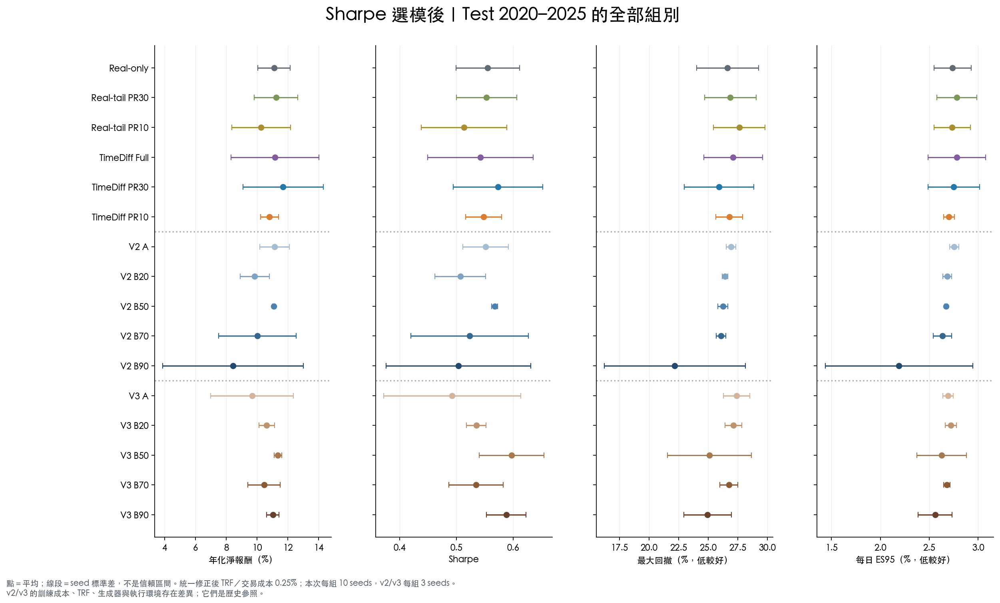

In [3]:
for split, title in [("train", "Train 2010–2017"), ("val", "Validation 2018–2019"), ("test", "Test 2020–2025")]:
    display(Markdown(f"### {title}"))
    display(metric_table(split))
    display(Markdown("**尾部風險與波動**"))
    display(additional_table(split, "risk"))
    display(Markdown("**交易成本與持股集中度**"))
    display(additional_table(split, "allocation"))
show_figure("03_selected_metrics_test")


## 訓練步數曲線與選模

每個 checkpoint 都在相同 split 連續評估。粗線為平均，色帶為 seeds 的 25–75% 範圍。**test 曲線僅用來診斷，沒有用 test 最高點挑模型或回頭調整訓練。**

每個 run 只選一個 validation Sharpe 最大的 checkpoint，同分取較早步數；該模型用於 train、validation、test 三個主要表格。最後 500k 的結果另列為敏感度分析。


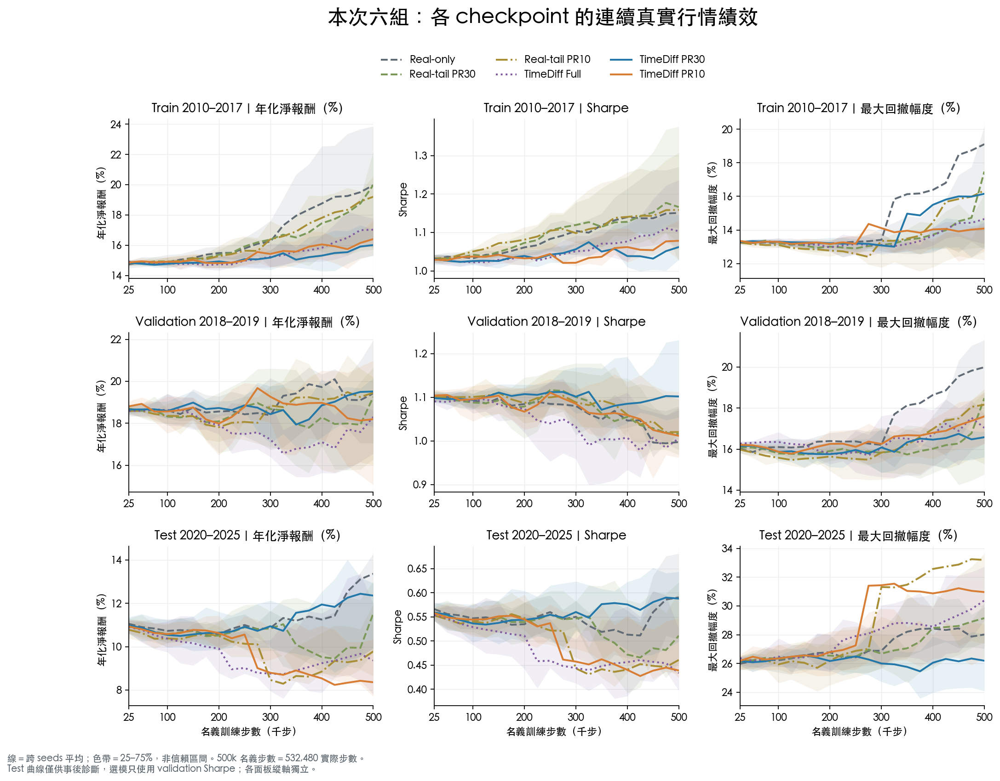

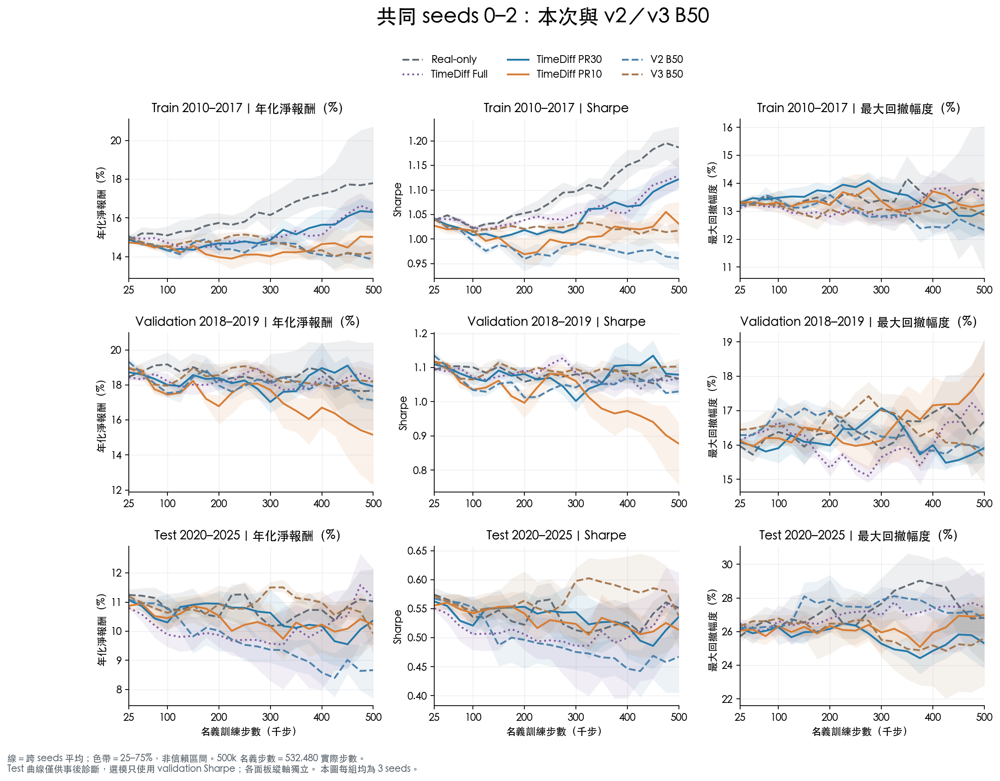

,seeds,selected_step_median,selected_step_min,selected_step_max,changes_from_original_log
group,,,,,
REAL_ONLY,10,262500.0,25000,425000,0
REAL_REPLAY_PR30_B50,10,275000.0,25000,475000,0
REAL_REPLAY_PR10_B50,10,312500.0,50000,375000,0
FULL_B50,10,187500.0,25000,500000,0
PR30_B50,10,450000.0,25000,500000,0
PR10_B50,10,137500.0,25000,425000,0
V2_A,3,150000.0,100000,175000,0
V2_B20,3,175000.0,150000,350000,0
V2_B50,3,25000.0,25000,25000,0


In [4]:
show_figure("01_current_checkpoint_curves")
show_figure("02_common_seed_version_curves")
choices = pd.read_csv(OUT / "selected_checkpoints.csv")
display(choices.groupby("group", sort=False).agg(seeds=("seed", "size"), selected_step_median=("nominal_timesteps", "median"), selected_step_min=("nominal_timesteps", "min"), selected_step_max=("nominal_timesteps", "max"), changes_from_original_log=("selection_changed_from_original_log", "sum")))


## Test 配對差異

配對單位是相同 seed，區間僅涵蓋訓練 seed 變異。不同市場時期、生成器訓練種子、條件抽樣種子皆未納入；多重比較未校正，作探索性解讀。

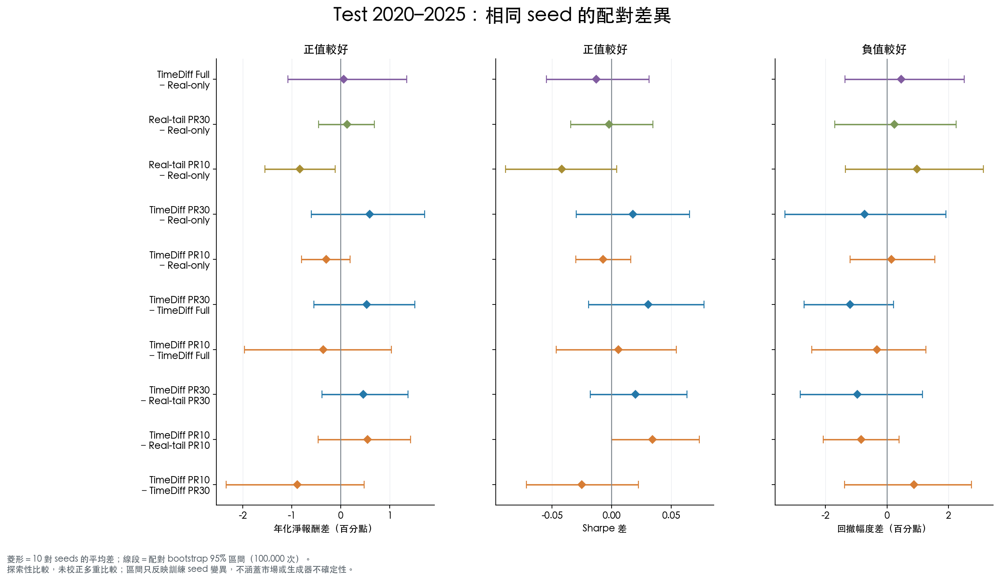

,split,treatment,control,metric,mean_difference,ci95_low,ci95_high,better_seeds,n_pairs
181,test,FULL_B50,REAL_ONLY,cagr_net_pct,0.0654,-1.0812,1.3471,4,10
182,test,FULL_B50,REAL_ONLY,sharpe,-0.0130,-0.0546,0.0314,3,10
184,test,FULL_B50,REAL_ONLY,mdd_pct,0.4710,-1.3743,2.5229,5,10
185,test,FULL_B50,REAL_ONLY,es95_daily_pct,0.0441,-0.1190,0.2276,3,10
190,test,REAL_REPLAY_PR30_B50,REAL_ONLY,cagr_net_pct,0.1307,-0.4516,0.6915,5,10
191,test,REAL_REPLAY_PR30_B50,REAL_ONLY,sharpe,-0.0021,-0.0343,0.0345,3,10
193,test,REAL_REPLAY_PR30_B50,REAL_ONLY,mdd_pct,0.2359,-1.6953,2.2609,5,10
194,test,REAL_REPLAY_PR30_B50,REAL_ONLY,es95_daily_pct,0.0422,-0.1027,0.1930,5,10
199,test,REAL_REPLAY_PR10_B50,REAL_ONLY,cagr_net_pct,-0.8373,-1.5516,-0.1143,3,10
200,test,REAL_REPLAY_PR10_B50,REAL_ONLY,sharpe,-0.0418,-0.0890,0.0041,3,10


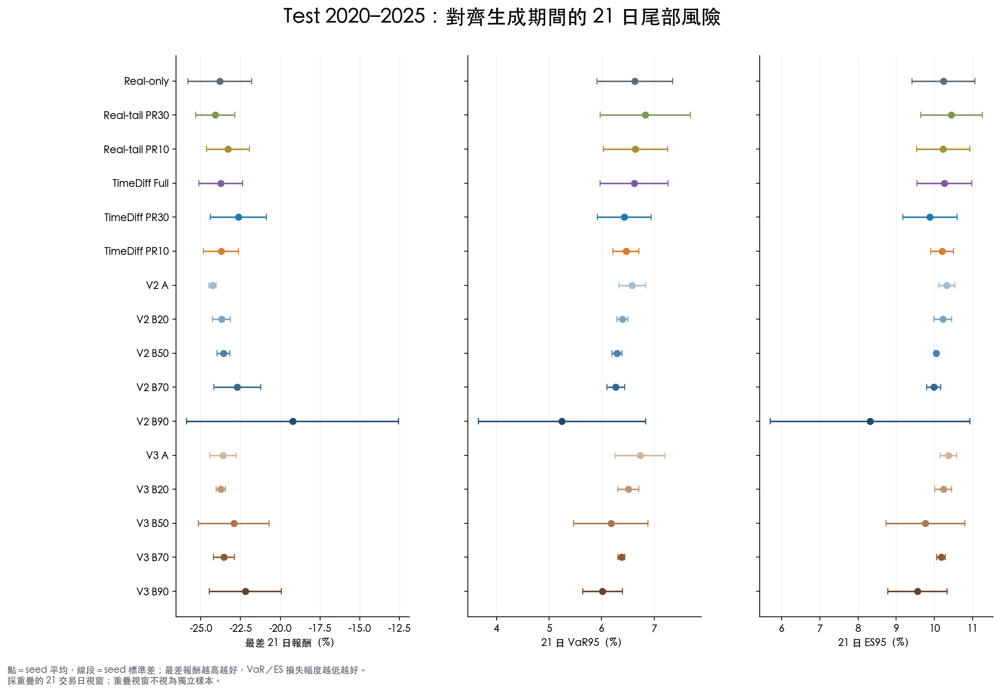

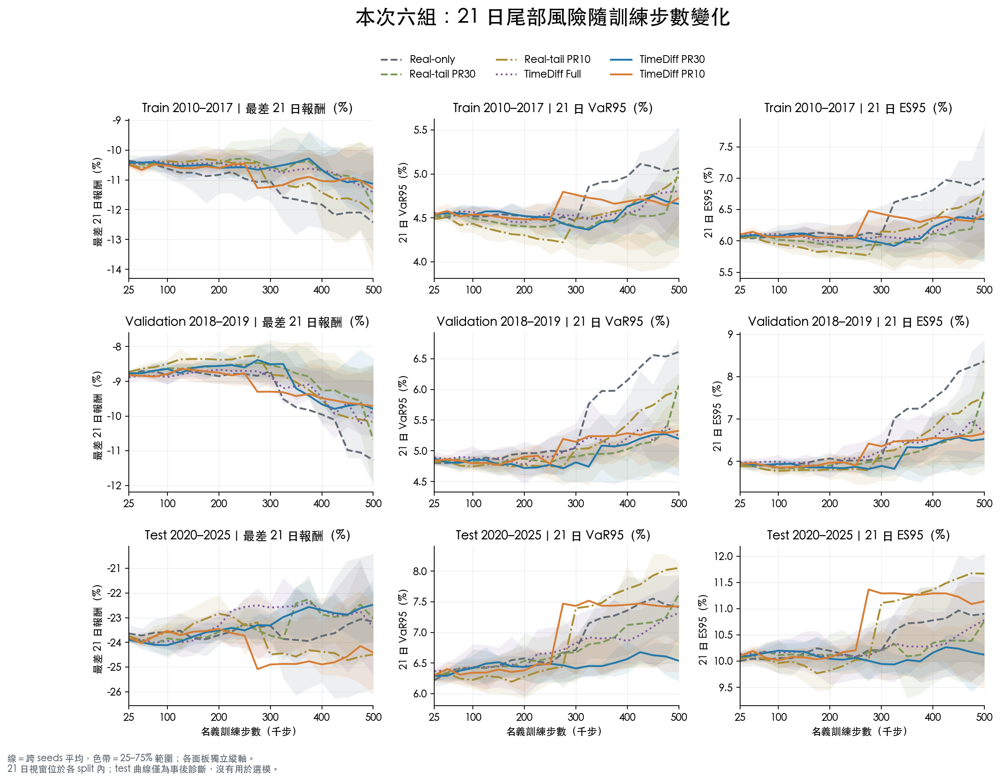

,group,n_seeds,worst_21d_return_pct_mean,worst_21d_return_pct_sd,var95_21d_pct_mean,es95_21d_pct_mean,es95_21d_pct_sd
2,REAL_ONLY,10,-23.811,2.006,6.630,10.241,0.827
5,REAL_REPLAY_PR30_B50,10,-24.090,1.246,6.831,10.447,0.810
8,REAL_REPLAY_PR10_B50,10,-23.286,1.354,6.641,10.230,0.697
11,FULL_B50,10,-23.751,1.374,6.618,10.264,0.719
14,PR30_B50,10,-22.640,1.756,6.431,9.886,0.712
17,PR10_B50,10,-23.732,1.094,6.466,10.203,0.298
20,V2_A,3,-24.262,0.228,6.582,10.326,0.212
23,V2_B20,3,-23.700,0.553,6.397,10.224,0.235
26,V2_B50,3,-23.568,0.405,6.293,10.050,0.049
29,V2_B70,3,-22.712,1.479,6.270,9.985,0.185


In [5]:
show_figure("05_test_paired_differences")
display(paired[(paired.split == "test") & paired.metric.isin(["cagr_net_pct", "sharpe", "mdd_pct", "es95_daily_pct"])].round(4))
show_figure("11_selected_horizon21_risk")
show_figure("12_current_horizon21_curves")
display(summary[summary.split == "test"][["group", "n_seeds", "worst_21d_return_pct_mean", "worst_21d_return_pct_sd", "var95_21d_pct_mean", "es95_21d_pct_mean", "es95_21d_pct_sd"]].round(3))


## 淨值、回撤與跨期間表現

買入持有參照包含現金各 1/11 的版本；另保存十檔股票等權、無初始現金版本。逐日中位數曲線不等於可直接交易的組合。

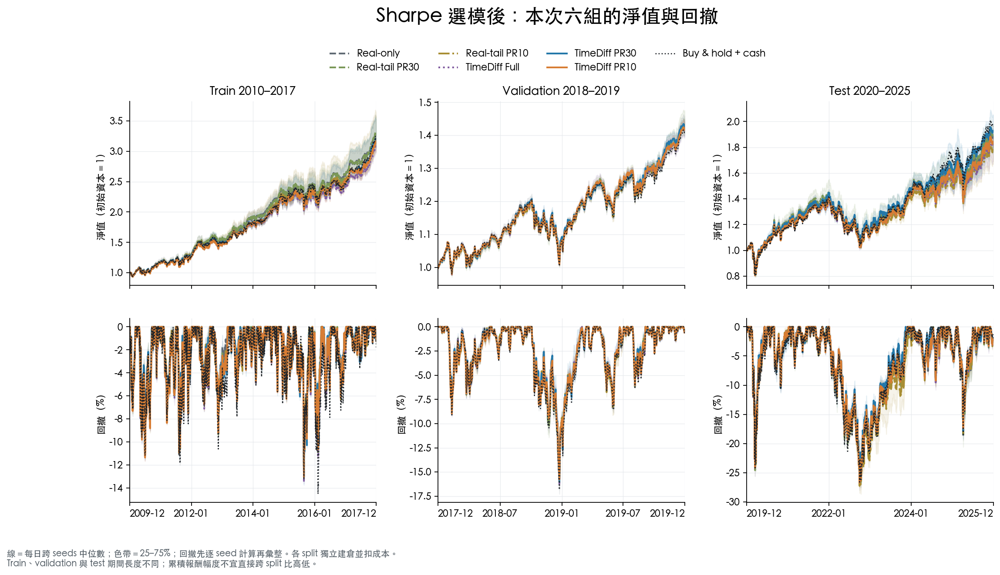

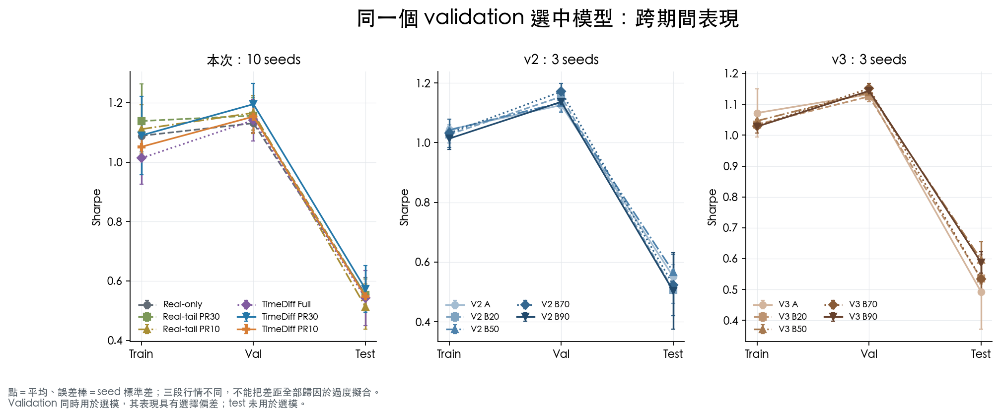

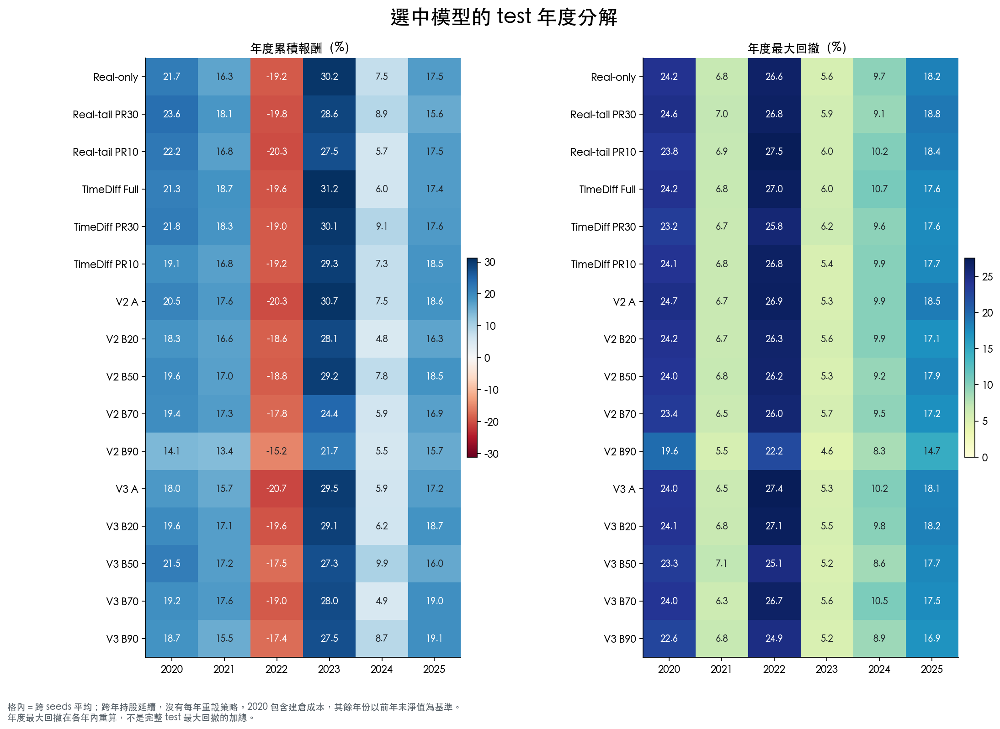

,group,split,return_pct,cagr_net_pct,sharpe,mdd_pct,es95_daily_pct
0,BUY_HOLD_CASH,train,218.392,15.602,1.001,14.521,2.092
1,BUY_HOLD_STOCKS,train,240.176,16.563,0.995,15.075,2.228
2,BUY_HOLD_CASH,val,41.289,18.906,1.079,16.817,2.512
3,BUY_HOLD_STOCKS,val,45.407,20.630,1.073,18.184,2.733
4,BUY_HOLD_CASH,test,96.294,11.930,0.598,26.614,2.747
5,BUY_HOLD_STOCKS,test,105.900,12.827,0.588,28.436,2.984


**Test 前後半段：各 seed 指標的平均**

cagr_net_pct            ...    sharpe          
period                  2020-2022 2023-2025  ... 2020-2022 2023-2025
group                                        ...                    
REAL_ONLY                   4.539    18.109  ...     0.198     1.170
REAL_REPLAY_PR30_B50        5.328    17.506  ...     0.225     1.126
REAL_REPLAY_PR10_B50        4.330    16.568  ...     0.187     1.063
FULL_B50                    4.957    17.779  ...     0.204     1.126
PR30_B50                    5.175    18.652  ...     0.217     1.182
PR10_B50                    3.977    18.123  ...     0.176     1.188
V2_A                        4.124    18.659  ...     0.179     1.188
V2_B20                      3.961    16.106  ...     0.178     1.066
V2_B50                      4.341    18.309  ...     0.194     1.208
V2_B70                      4.788    15.570  ...     0.220     1.052
V2_B90                      3.035    14.181  ...     0.149     1.074
V3_A                        2.662    17.215  ...     0.119     1.126
V3_B20                      4.015    17.700  ...     0.177     1.141
V3_B50                      5.469    17.601  ...     0.249     1.209
V3_B70                      4.329    16.973  ...     0.193     1.113
V3_B90                      4.249    18.281  ...     0.198     1.246

[16 rows x 6 columns]

**2020 Q1 壓力期間：累積報酬與風險（沒有將季度報酬年化）**

,return_pct,mdd_pct,es95_21d_pct,stock_weight_pct
group,,,,
REAL_ONLY,-9.265,24.236,22.512,89.880
REAL_REPLAY_PR30_B50,-10.277,24.621,22.843,90.174
REAL_REPLAY_PR10_B50,-9.724,23.777,22.120,90.066
FULL_B50,-8.881,24.236,22.440,90.444
PR30_B50,-8.425,23.193,21.546,88.978
PR10_B50,-9.859,24.143,22.486,91.122
V2_A,-9.917,24.734,22.782,90.156
V2_B20,-10.811,24.155,22.341,91.223
V2_B50,-9.983,23.980,22.323,90.860


In [6]:
show_figure("04_selected_paths")
show_figure("06_generalization")
show_figure("08_test_annual_heatmap")
display(pd.read_csv(OUT / "benchmark_metrics.csv")[["group", "split", "return_pct", "cagr_net_pct", "sharpe", "mdd_pct", "es95_daily_pct"]].round(3))
subperiod = pd.read_csv(OUT / "selected_subperiod_metrics.csv")
display(Markdown("**Test 前後半段：各 seed 指標的平均**"))
halves = subperiod[(subperiod.split == "test") & subperiod.period.isin(["2020-2022", "2023-2025"])]
display(halves.pivot_table(index="group", columns="period", values=["cagr_net_pct", "sharpe", "mdd_pct"]).reindex(ORDER).round(3))
display(Markdown("**2020 Q1 壓力期間：累積報酬與風險（沒有將季度報酬年化）**"))
display(subperiod[(subperiod.split == "test") & (subperiod.period == "2020Q1")].groupby("group")[["return_pct", "mdd_pct", "es95_21d_pct", "stock_weight_pct"]].mean().reindex(ORDER).round(3))


## 持股比例與集中風險

以下先展示本次六組的完整持股時間圖。每組三欄分別為 train、validation、test；上排是跨 seeds 平均實際收盤權重，下排呈現總曝險與最大單股權重的 seeds 中位數及 IQR。完整 v2、v3 圖也在下方索引。

最大單股權重先逐 seed／逐日計算，再彙整，避免不同 seeds 集中在不同股票時，被平均權重掩蓋。


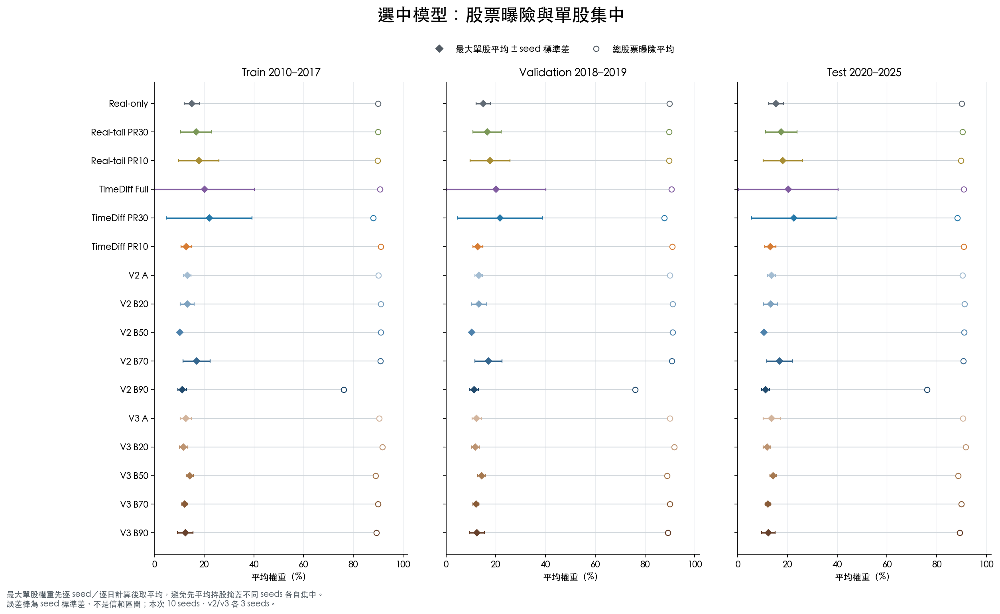

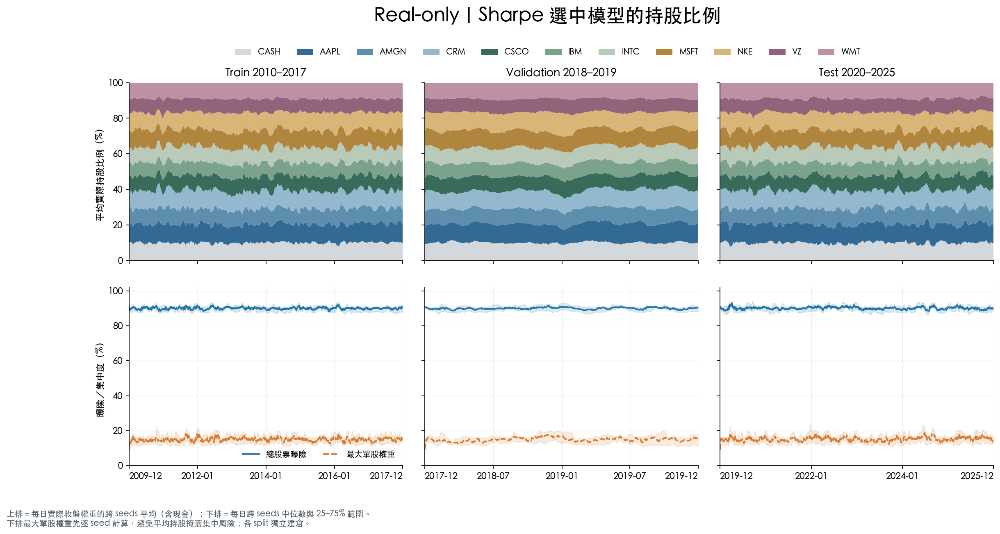

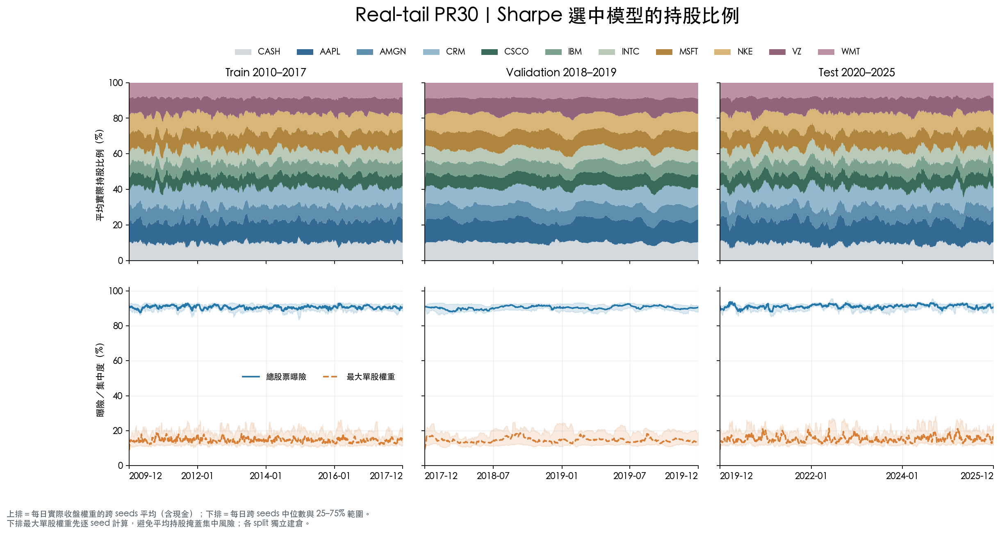

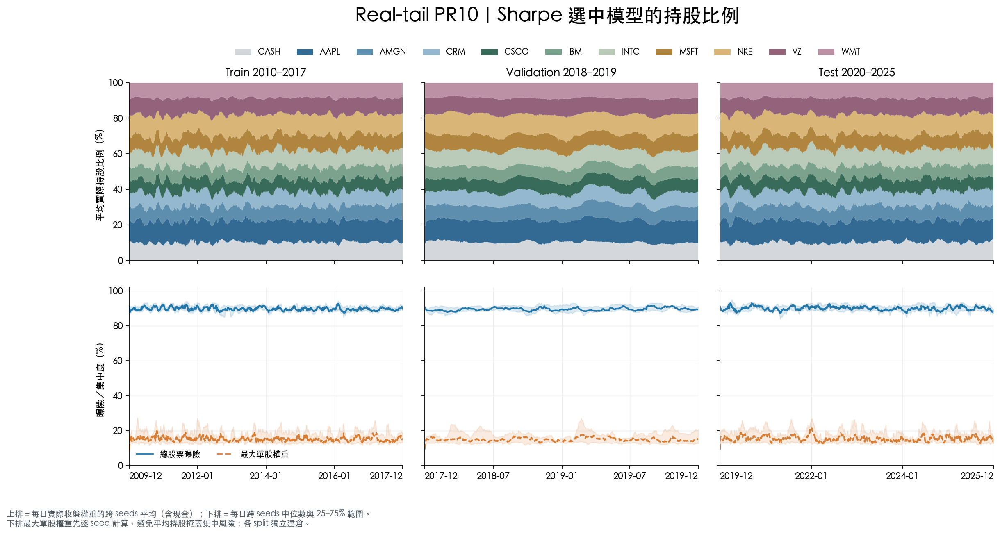

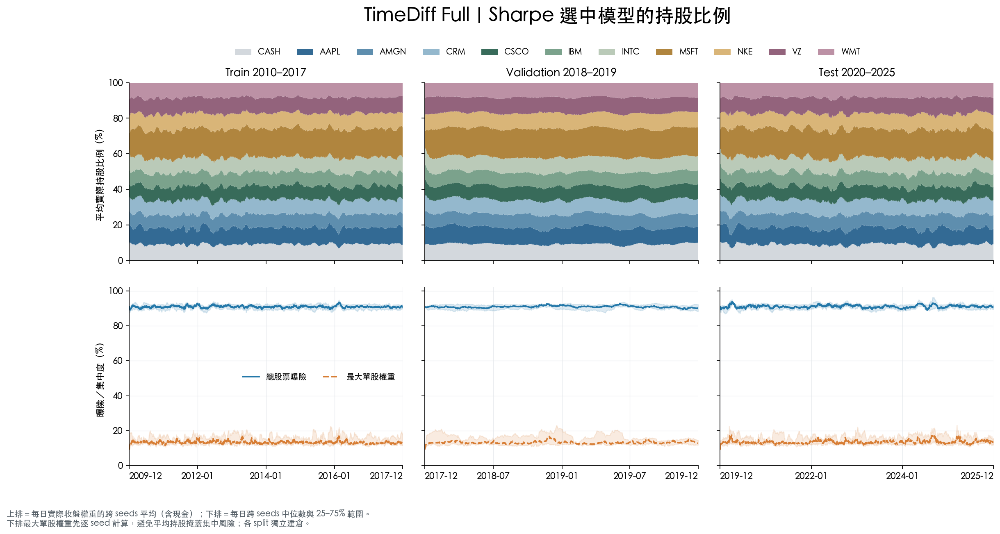

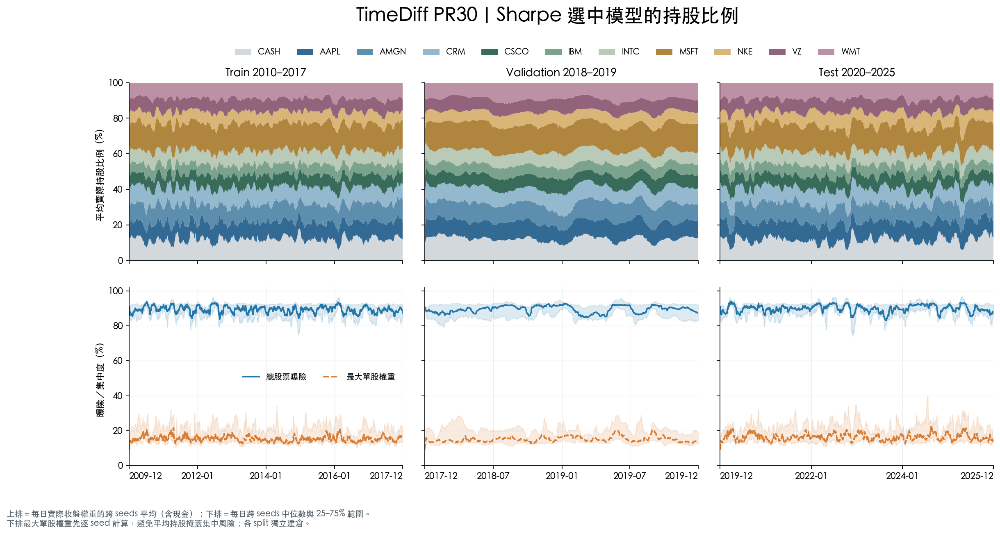

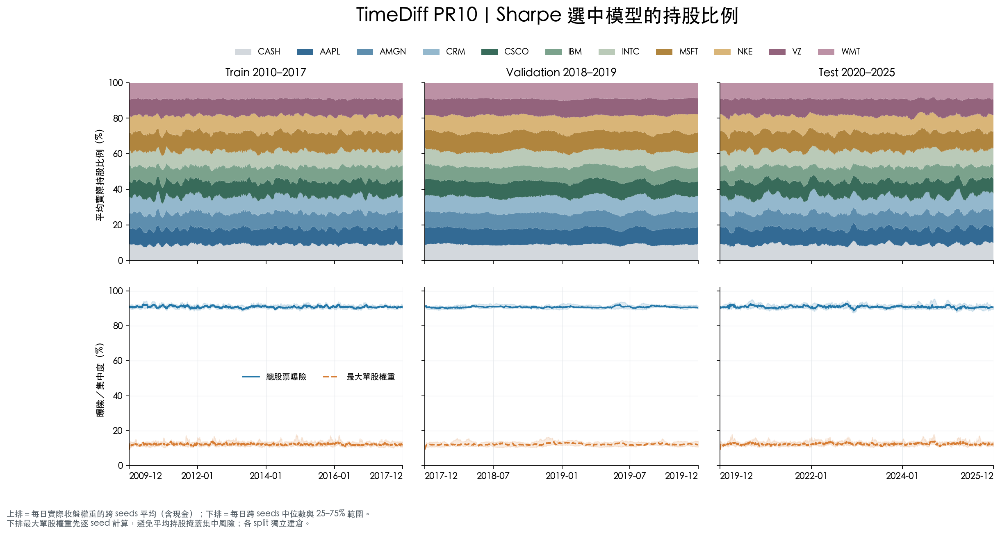

**Test 單股權重曾超過 60% 的 seeds**：僅作持股診斷，所有 seeds 均保留在績效統計內。

,group,seed,nominal_timesteps,asset,mean_weight_pct,max_single_stock_weight_pct,cagr_net_pct,mdd_pct
0,REAL_REPLAY_PR30_B50,5,350000,CRM,22.687,81.777,10.004,31.458
1,FULL_B50,7,500000,MSFT,76.732,78.282,17.659,33.452
2,PR30_B50,5,500000,NKE,10.740,60.419,11.856,28.026
3,PR30_B50,7,500000,MSFT,68.636,70.423,17.366,32.442


In [7]:
show_figure("09_exposure_concentration")
for group in CURRENT:
    show_figure(f"by_group/holdings_{group}")
display(Markdown("**Test 單股權重曾超過 60% 的 seeds**：僅作持股診斷，所有 seeds 均保留在績效統計內。"))
asset = pd.read_csv(OUT / "selected_asset_weights.csv")
asset = asset[(asset.split == "test") & (asset.asset != "CASH")].sort_values("mean_weight_pct", ascending=False).drop_duplicates(["group", "seed"])
concentrated = selected[(selected.split == "test") & (selected.max_single_stock_weight_pct > 60)].merge(asset[["group", "seed", "asset", "mean_weight_pct"]], on=["group", "seed"], validate="one_to_one")
display(concentrated[["group", "seed", "nominal_timesteps", "asset", "mean_weight_pct", "max_single_stock_weight_pct", "cagr_net_pct", "mdd_pct"]].round(3))


## 真實訓練 episodes 與最後模型敏感度

訓練 episode reward 受抽中的行情、episode 長度和成本設定影響，因此同時提供每交易日正規化版本。v2、v3 的 scenario 是固定壓力情境編號，並非本次的 full／tail 來源池，因此其尾部池比例標示為不適用。

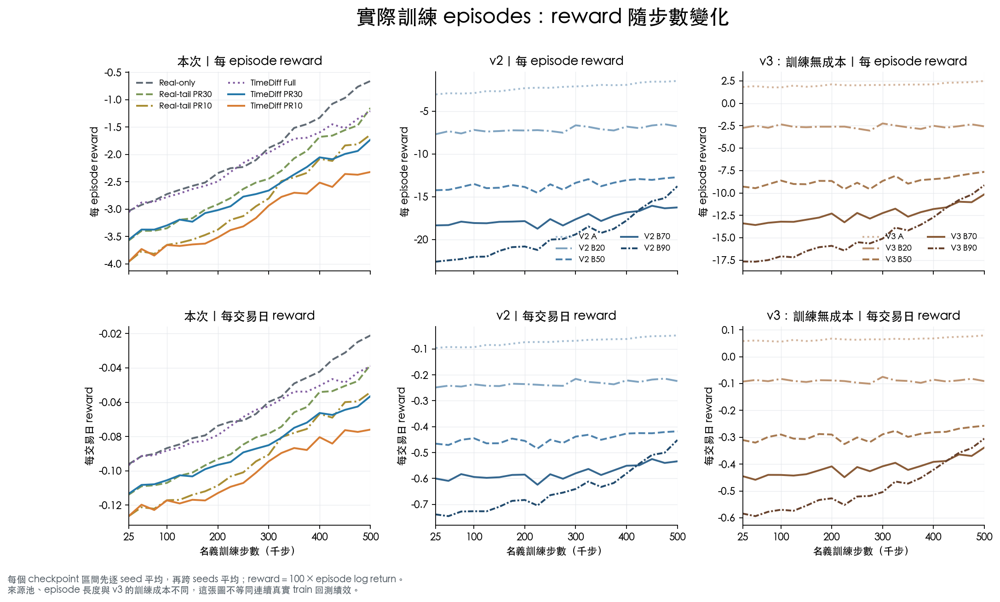

,replacement_pct,synthetic_pct,real_replay_pct,tail_pool_all_episodes_pct,tail_pool_replacement_pct,mean_length
group,,,,,,
REAL_ONLY,0.000,0.000,0.000,0.0,0.0,31.478
REAL_REPLAY_PR30_B50,50.105,0.000,50.105,15.263,30.461,31.492
REAL_REPLAY_PR10_B50,50.105,0.000,50.105,14.886,29.71,31.492
FULL_B50,50.105,50.105,0.000,0.0,0.0,31.492
PR30_B50,50.105,50.105,0.000,15.263,30.461,31.492
PR10_B50,50.105,50.105,0.000,14.886,29.71,31.492
V2_A,0.000,0.000,0.000,不適用,不適用,31.433
V2_B20,20.080,20.080,0.000,不適用,不適用,31.500
V2_B50,50.001,50.001,0.000,不適用,不適用,31.500


,group,sharpe_mean_selected,cagr_net_pct_mean_selected,mdd_pct_mean_selected,sharpe_mean_500k,cagr_net_pct_mean_500k,mdd_pct_mean_500k
0,REAL_ONLY,0.555,11.096,26.634,0.591,13.364,28.017
1,REAL_REPLAY_PR30_B50,0.553,11.227,26.870,0.511,11.526,29.156
2,REAL_REPLAY_PR10_B50,0.514,10.259,27.617,0.461,9.785,33.201
3,FULL_B50,0.542,11.162,27.105,0.434,9.366,30.383
4,PR30_B50,0.573,11.691,25.898,0.588,12.359,26.198
5,PR10_B50,0.548,10.804,26.776,0.439,8.361,30.967
6,V2_A,0.552,11.133,26.919,0.559,11.472,28.948
7,V2_B20,0.507,9.849,26.425,0.524,9.515,25.477
8,V2_B50,0.568,11.087,26.240,0.467,8.662,26.783
9,V2_B70,0.524,10.013,26.075,0.500,9.373,25.439


### 共同 seeds 0–2 的 test 表格

,seeds,累積報酬 %,年化淨報酬 %,Sharpe,Sortino,Calmar,最大回撤 %,每日 ES95 %,平均股票曝險 %
group,,,,,,,,,
REAL_ONLY,3,85.56 ± 6.37,10.88 ± 0.64,0.528 ± 0.059,0.750 ± 0.087,0.392 ± 0.063,28.16 ± 3.16,2.84 ± 0.21,90.49 ± 2.18
REAL_REPLAY_PR30_B50,3,88.01 ± 7.14,11.12 ± 0.70,0.554 ± 0.018,0.787 ± 0.027,0.419 ± 0.026,26.67 ± 0.90,2.75 ± 0.12,89.99 ± 0.61
REAL_REPLAY_PR10_B50,3,73.97 ± 9.59,9.68 ± 1.02,0.510 ± 0.073,0.722 ± 0.105,0.373 ± 0.080,26.49 ± 3.15,2.64 ± 0.14,89.14 ± 2.36
FULL_B50,3,83.37 ± 32.28,10.51 ± 3.14,0.527 ± 0.157,0.750 ± 0.229,0.403 ± 0.142,26.51 ± 1.58,2.74 ± 0.17,90.60 ± 3.85
PR30_B50,3,80.68 ± 14.46,10.36 ± 1.51,0.530 ± 0.069,0.754 ± 0.091,0.413 ± 0.032,25.08 ± 2.18,2.67 ± 0.10,90.52 ± 3.83
PR10_B50,3,83.24 ± 2.06,10.65 ± 0.21,0.540 ± 0.011,0.767 ± 0.015,0.398 ± 0.018,26.88 ± 1.41,2.69 ± 0.07,90.85 ± 1.05
V2_A,3,88.21 ± 9.54,11.13 ± 0.95,0.552 ± 0.040,0.784 ± 0.058,0.415 ± 0.039,26.92 ± 0.41,2.75 ± 0.05,90.36 ± 0.85
V2_B20,3,75.57 ± 8.99,9.85 ± 0.94,0.507 ± 0.045,0.718 ± 0.066,0.374 ± 0.033,26.42 ± 0.23,2.68 ± 0.05,91.19 ± 3.50
V2_B50,3,87.61 ± 0.72,11.09 ± 0.07,0.568 ± 0.005,0.806 ± 0.007,0.424 ± 0.009,26.24 ± 0.42,2.67 ± 0.01,91.05 ± 0.10


In [8]:
show_figure("07_training_episode_rewards")
sampling = pd.read_csv(OUT / "episode_sampling.csv")
display(sampling.groupby("group", sort=False)[["replacement_pct", "synthetic_pct", "real_replay_pct", "tail_pool_all_episodes_pct", "tail_pool_replacement_pct", "mean_length"]].mean().round(3).fillna("不適用"))
final = pd.read_csv(OUT / "fixed_final_summary.csv")
z = summary[summary.split == "test"][["group", "sharpe_mean", "cagr_net_pct_mean", "mdd_pct_mean"]].merge(final[final.split == "test"][["group", "sharpe_mean", "cagr_net_pct_mean", "mdd_pct_mean"]], on="group", suffixes=("_selected", "_500k"))
display(z.round(3))
display(Markdown("### 共同 seeds 0–2 的 test 表格"))
display(metric_table("test", common=True))


## 全部圖表與資料索引

每組皆有績效、風險與成本、持股集中度三套步數曲線，以及持股比例時間圖；每張圖均提供 PNG 與可縮放 SVG。

In [9]:
from urllib.parse import quote
rows = []
for group in ORDER:
    links = []
    for prefix, label in [("curves", "績效步數曲線"), ("curves_risk", "風險／成本步數曲線"), ("curves_allocation", "集中度／21日風險曲線"), ("holdings", "持股時間圖")]:
        path = FIG / "by_group" / f"{prefix}_{group}.png"
        assert path.exists()
        links.append(f"[{label}]({path})")
    rows.append(f"| {group} | " + " · ".join(links) + " |")
display(Markdown("| 組別 | 圖表 |\n|---|---|\n" + "\n".join(rows)))
for name in ["selected_metrics.csv", "selected_summary.csv", "all_checkpoint_metrics.csv", "selected_checkpoints.csv", "selected_summary_common_seeds0_2.csv", "paired_seed_differences.csv", "selected_subperiod_metrics.csv", "selected_asset_weights.csv", "checkpoint_selection_sensitivity.csv", "generation_quality_comparison.csv"]:
    display(Markdown(f"- [{name}]({OUT / name})"))


| 組別 | 圖表 |
|---|---|
| REAL_ONLY | [績效步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_REAL_ONLY.png) · [風險／成本步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_risk_REAL_ONLY.png) · [集中度／21日風險曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_allocation_REAL_ONLY.png) · [持股時間圖](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/holdings_REAL_ONLY.png) |
| REAL_REPLAY_PR30_B50 | [績效步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_REAL_REPLAY_PR30_B50.png) · [風險／成本步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_risk_REAL_REPLAY_PR30_B50.png) · [集中度／21日風險曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_allocation_REAL_REPLAY_PR30_B50.png) · [持股時間圖](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/holdings_REAL_REPLAY_PR30_B50.png) |
| REAL_REPLAY_PR10_B50 | [績效步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_REAL_REPLAY_PR10_B50.png) · [風險／成本步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_risk_REAL_REPLAY_PR10_B50.png) · [集中度／21日風險曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_allocation_REAL_REPLAY_PR10_B50.png) · [持股時間圖](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/holdings_REAL_REPLAY_PR10_B50.png) |
| FULL_B50 | [績效步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_FULL_B50.png) · [風險／成本步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_risk_FULL_B50.png) · [集中度／21日風險曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_allocation_FULL_B50.png) · [持股時間圖](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/holdings_FULL_B50.png) |
| PR30_B50 | [績效步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_PR30_B50.png) · [風險／成本步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_risk_PR30_B50.png) · [集中度／21日風險曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_allocation_PR30_B50.png) · [持股時間圖](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/holdings_PR30_B50.png) |
| PR10_B50 | [績效步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_PR10_B50.png) · [風險／成本步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_risk_PR10_B50.png) · [集中度／21日風險曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_allocation_PR10_B50.png) · [持股時間圖](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/holdings_PR10_B50.png) |
| V2_A | [績效步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_V2_A.png) · [風險／成本步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_risk_V2_A.png) · [集中度／21日風險曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_allocation_V2_A.png) · [持股時間圖](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/holdings_V2_A.png) |
| V2_B20 | [績效步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_V2_B20.png) · [風險／成本步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_risk_V2_B20.png) · [集中度／21日風險曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_allocation_V2_B20.png) · [持股時間圖](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/holdings_V2_B20.png) |
| V2_B50 | [績效步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_V2_B50.png) · [風險／成本步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_risk_V2_B50.png) · [集中度／21日風險曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_allocation_V2_B50.png) · [持股時間圖](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/holdings_V2_B50.png) |
| V2_B70 | [績效步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_V2_B70.png) · [風險／成本步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_risk_V2_B70.png) · [集中度／21日風險曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_allocation_V2_B70.png) · [持股時間圖](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/holdings_V2_B70.png) |
| V2_B90 | [績效步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_V2_B90.png) · [風險／成本步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_risk_V2_B90.png) · [集中度／21日風險曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_allocation_V2_B90.png) · [持股時間圖](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/holdings_V2_B90.png) |
| V3_A | [績效步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_V3_A.png) · [風險／成本步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_risk_V3_A.png) · [集中度／21日風險曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_allocation_V3_A.png) · [持股時間圖](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/holdings_V3_A.png) |
| V3_B20 | [績效步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_V3_B20.png) · [風險／成本步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_risk_V3_B20.png) · [集中度／21日風險曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_allocation_V3_B20.png) · [持股時間圖](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/holdings_V3_B20.png) |
| V3_B50 | [績效步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_V3_B50.png) · [風險／成本步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_risk_V3_B50.png) · [集中度／21日風險曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_allocation_V3_B50.png) · [持股時間圖](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/holdings_V3_B50.png) |
| V3_B70 | [績效步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_V3_B70.png) · [風險／成本步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_risk_V3_B70.png) · [集中度／21日風險曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_allocation_V3_B70.png) · [持股時間圖](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/holdings_V3_B70.png) |
| V3_B90 | [績效步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_V3_B90.png) · [風險／成本步數曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_risk_V3_B90.png) · [集中度／21日風險曲線](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/curves_allocation_V3_B90.png) · [持股時間圖](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/figures/by_group/holdings_V3_B90.png) |

- [selected_metrics.csv](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/selected_metrics.csv)

- [selected_summary.csv](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/selected_summary.csv)

- [all_checkpoint_metrics.csv](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/all_checkpoint_metrics.csv)

- [selected_checkpoints.csv](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/selected_checkpoints.csv)

...

- [paired_seed_differences.csv](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/paired_seed_differences.csv)

- [selected_subperiod_metrics.csv](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/selected_subperiod_metrics.csv)

- [selected_asset_weights.csv](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/selected_asset_weights.csv)

- [checkpoint_selection_sensitivity.csv](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/checkpoint_selection_sensitivity.csv)

- [generation_quality_comparison.csv](/Users/chuanwei/Files/Projects/nycu_fintech/FinRL_Exp/results/scenario_mix/comprehensive_20261019/generation_quality_comparison.csv)

## 方法與限制

- Sharpe：日 log return 平均／樣本標準差 × √252，無風險利率設為 0。Sortino 的 downside deviation 以全部交易日為分母。
- 年化淨報酬包含建倉成本；為與既有紀錄一致，Calmar 分子沿用平均日 log return 年化值，建倉成本位於初始淨值，不算成單日報酬。
- 最大回撤為每日淨值相對當時歷史高點的最大跌幅；ES95 為最低 5% 簡單日報酬的平均損失。
- 21 日風險採各 split 內重疊的 21 交易日淨值報酬；最差報酬保留報酬原始正負號，VaR／ES 損失記正、收益記負。重疊視窗不當成獨立樣本。
- 年度與 test 子期間延續原持股，沒有逐年重設；只在整個 split 開始時收建倉成本。
- Validation 同時用於 TimeDiff 與 PPO 的選模，具有選擇偏差。v2、v3 的 test 曾在先前實驗被檢視，本比較不宣稱是全新盲測。
- 本次只代表單一股票組合、固定資料期間與單一生成資料批次；重疊視窗、重複條件與多條生成路徑不是獨立市場事件。
- 生成器原始價格檔與 PPO 延伸價格檔存在微小調整價修訂，重疊價格最大相對差約 1.282 ppm；所有 PPO 比較均使用同一延伸價格檔。
- v2、v3 的訓練環境、TRF 與生成器條件不同，統一重算評估可以消除評分公式差異，但無法消除訓練差異。

Notebook 以單一程序 IPython 從頭執行並保存輸出，符合此專案的無 socket 驗證方式；沒有啟動 Jupyter kernel。


In [10]:
audit = json.loads((OUT / "analysis_manifest.json").read_text())
display(pd.DataFrame({"item": ["groups", "runs", "checkpoints", "split_evaluations", "selected_split_rows"], "count": [len(audit["groups"]), audit["runs"], audit["checkpoints"], audit["split_evaluations"], audit["selected_split_rows"]]}))
display(pd.read_csv(OUT / "v2_saved_model_equivalence.csv")[["group", "seed", "original_sharpe_selected_step", "policy_equal"]])
assert pd.read_csv(OUT / "v2_saved_model_equivalence.csv").policy_equal.all()


,item,count
0,groups,16
1,runs,90
2,checkpoints,1800
3,split_evaluations,5400
4,selected_split_rows,270


,group,seed,original_sharpe_selected_step,policy_equal
0,V2_A,0,175000,True
1,V2_A,1,100000,True
2,V2_A,2,150000,True
3,V2_B20,0,175000,True
4,V2_B20,1,150000,True
5,V2_B20,2,350000,True
6,V2_B50,0,25000,True
7,V2_B50,1,25000,True
8,V2_B50,2,25000,True
9,V2_B70,0,50000,True
